# SISPS-BATT-INT-CAL

Calibration of SISPS Battery Interposer for Lead Acid Battery Freezing Extent Measurement.

## Setup

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

from matplotlib.figure import Figure
from matplotlib.ticker import FuncFormatter

In [14]:
plt.rcParams.update(
    {
        "figure.dpi": 600,
    }
)

## Data Import

In [15]:
SERIAL_DATA_PATH = "../Data/Serial"
VBATT_DATA_PATH = "../Data/VBATT"

## VBAT Data



In [16]:
def load_vbatt_data(file_path):
    file = os.listdir(file_path)[0]
    df = pd.read_csv(
        os.path.join(file_path, file),
        index_col=0,
    )
    return df


vbatt_df = load_vbatt_data(VBATT_DATA_PATH)

### Serial Data

In [17]:
def load_serial_data(file_path: str) -> pd.DataFrame:
    """
    Load serial data from a Text file and return it as a DataFrame.
    """
    HEADER_LINES = 23

    result = {}
    battery = os.path.basename(file_path).split(" ")[0]

    print(f"Loading serial data from: {file_path} for battery: {battery}")
    with open(file_path, "r") as file:
        content = file.read()

        lines = content.splitlines()
        header = "\n".join(lines[:HEADER_LINES])
        data = "\n".join(lines[HEADER_LINES:])

    result["battery"] = battery
    result["header"] = header

    def parse_data(data: str) -> pd.DataFrame:
        VARIABLES = ["Temp+", "Temp-", "Delta T", "Vrms", "VrmsNull", "Vbatt"]
        dataframe = pd.DataFrame(columns=VARIABLES)

        line_number = 0
        for line in data.splitlines():
            for var in VARIABLES:
                data_point = line.split(f"{var}:")[1].split()[0]
                dataframe.at[line_number, var] = float(data_point)

            line_number += 1

        return dataframe

    result = parse_data(data)
    result.attrs = {"battery": battery, "header": header}

    return result


dataframes = []

for file_name in os.listdir(SERIAL_DATA_PATH):
    if file_name.endswith(".txt"):
        file_path = os.path.join(SERIAL_DATA_PATH, file_name)
        df = load_serial_data(file_path)
        dataframes.append(df)

Loading serial data from: ../Data/Serial/C13 Serial Output.txt for battery: C13
Loading serial data from: ../Data/Serial/C12 Serial Output.txt for battery: C12
Loading serial data from: ../Data/Serial/C11 Serial Output.txt for battery: C11
Loading serial data from: ../Data/Serial/C08 Serial Output.txt for battery: C08
Loading serial data from: ../Data/Serial/C14 Serial Output.txt for battery: C14
Loading serial data from: ../Data/Serial/C10 Serial Output.txt for battery: C10
Loading serial data from: ../Data/Serial/C09 Serial Output.txt for battery: C09
Loading serial data from: ../Data/Serial/C05 Serial Output.txt for battery: C05
Loading serial data from: ../Data/Serial/C01 Serial Output.txt for battery: C01
Loading serial data from: ../Data/Serial/C04 Serial Output.txt for battery: C04
Loading serial data from: ../Data/Serial/C02 Serial Output.txt for battery: C02
Loading serial data from: ../Data/Serial/C07 Serial Output.txt for battery: C07
Loading serial data from: ../Data/Serial

### Data Preprocessing

In [18]:
dataframes.sort(key=lambda df: df.attrs["battery"])

for df in dataframes:
    df["Vrms"] = df["Vrms"] / 1000
    df["VrmsNull"] = df["VrmsNull"] / 1000
    df["Delta T"] = df["Delta T"] / 1000

## Impedance

In [19]:
def get_vrms(vrms_list: list) -> float:
    return pd.Series(vrms_list).tail(3).mean()


EIS_CURRENT = 0.150


def impedance(vrms: float, vrms_null: float, current: float) -> float:
    return (vrms - vrms_null) / current


impedances = {}

for df in dataframes:
    battery = df.attrs["battery"]
    vrms = get_vrms(df["Vrms"])
    vrms_null = get_vrms(df["VrmsNull"])

    impedances[battery] = impedance(vrms, vrms_null, EIS_CURRENT)

print(impedances)

{'C01': np.float64(0.2148466666666667), 'C02': np.float64(0.19461333333333336), 'C03': np.float64(0.21516444444444446), 'C04': np.float64(0.18516666666666665), 'C05': np.float64(0.18669111111111109), 'C06': np.float64(0.15391555555555558), 'C07': np.float64(0.21090444444444445), 'C08': np.float64(0.15279333333333336), 'C09': np.float64(0.17087999999999998), 'C10': np.float64(0.17908444444444443), 'C11': np.float64(0.22361111111111115), 'C12': np.float64(0.2799288888888889), 'C13': np.float64(0.45990444444444445), 'C14': np.float64(0.8144266666666666)}


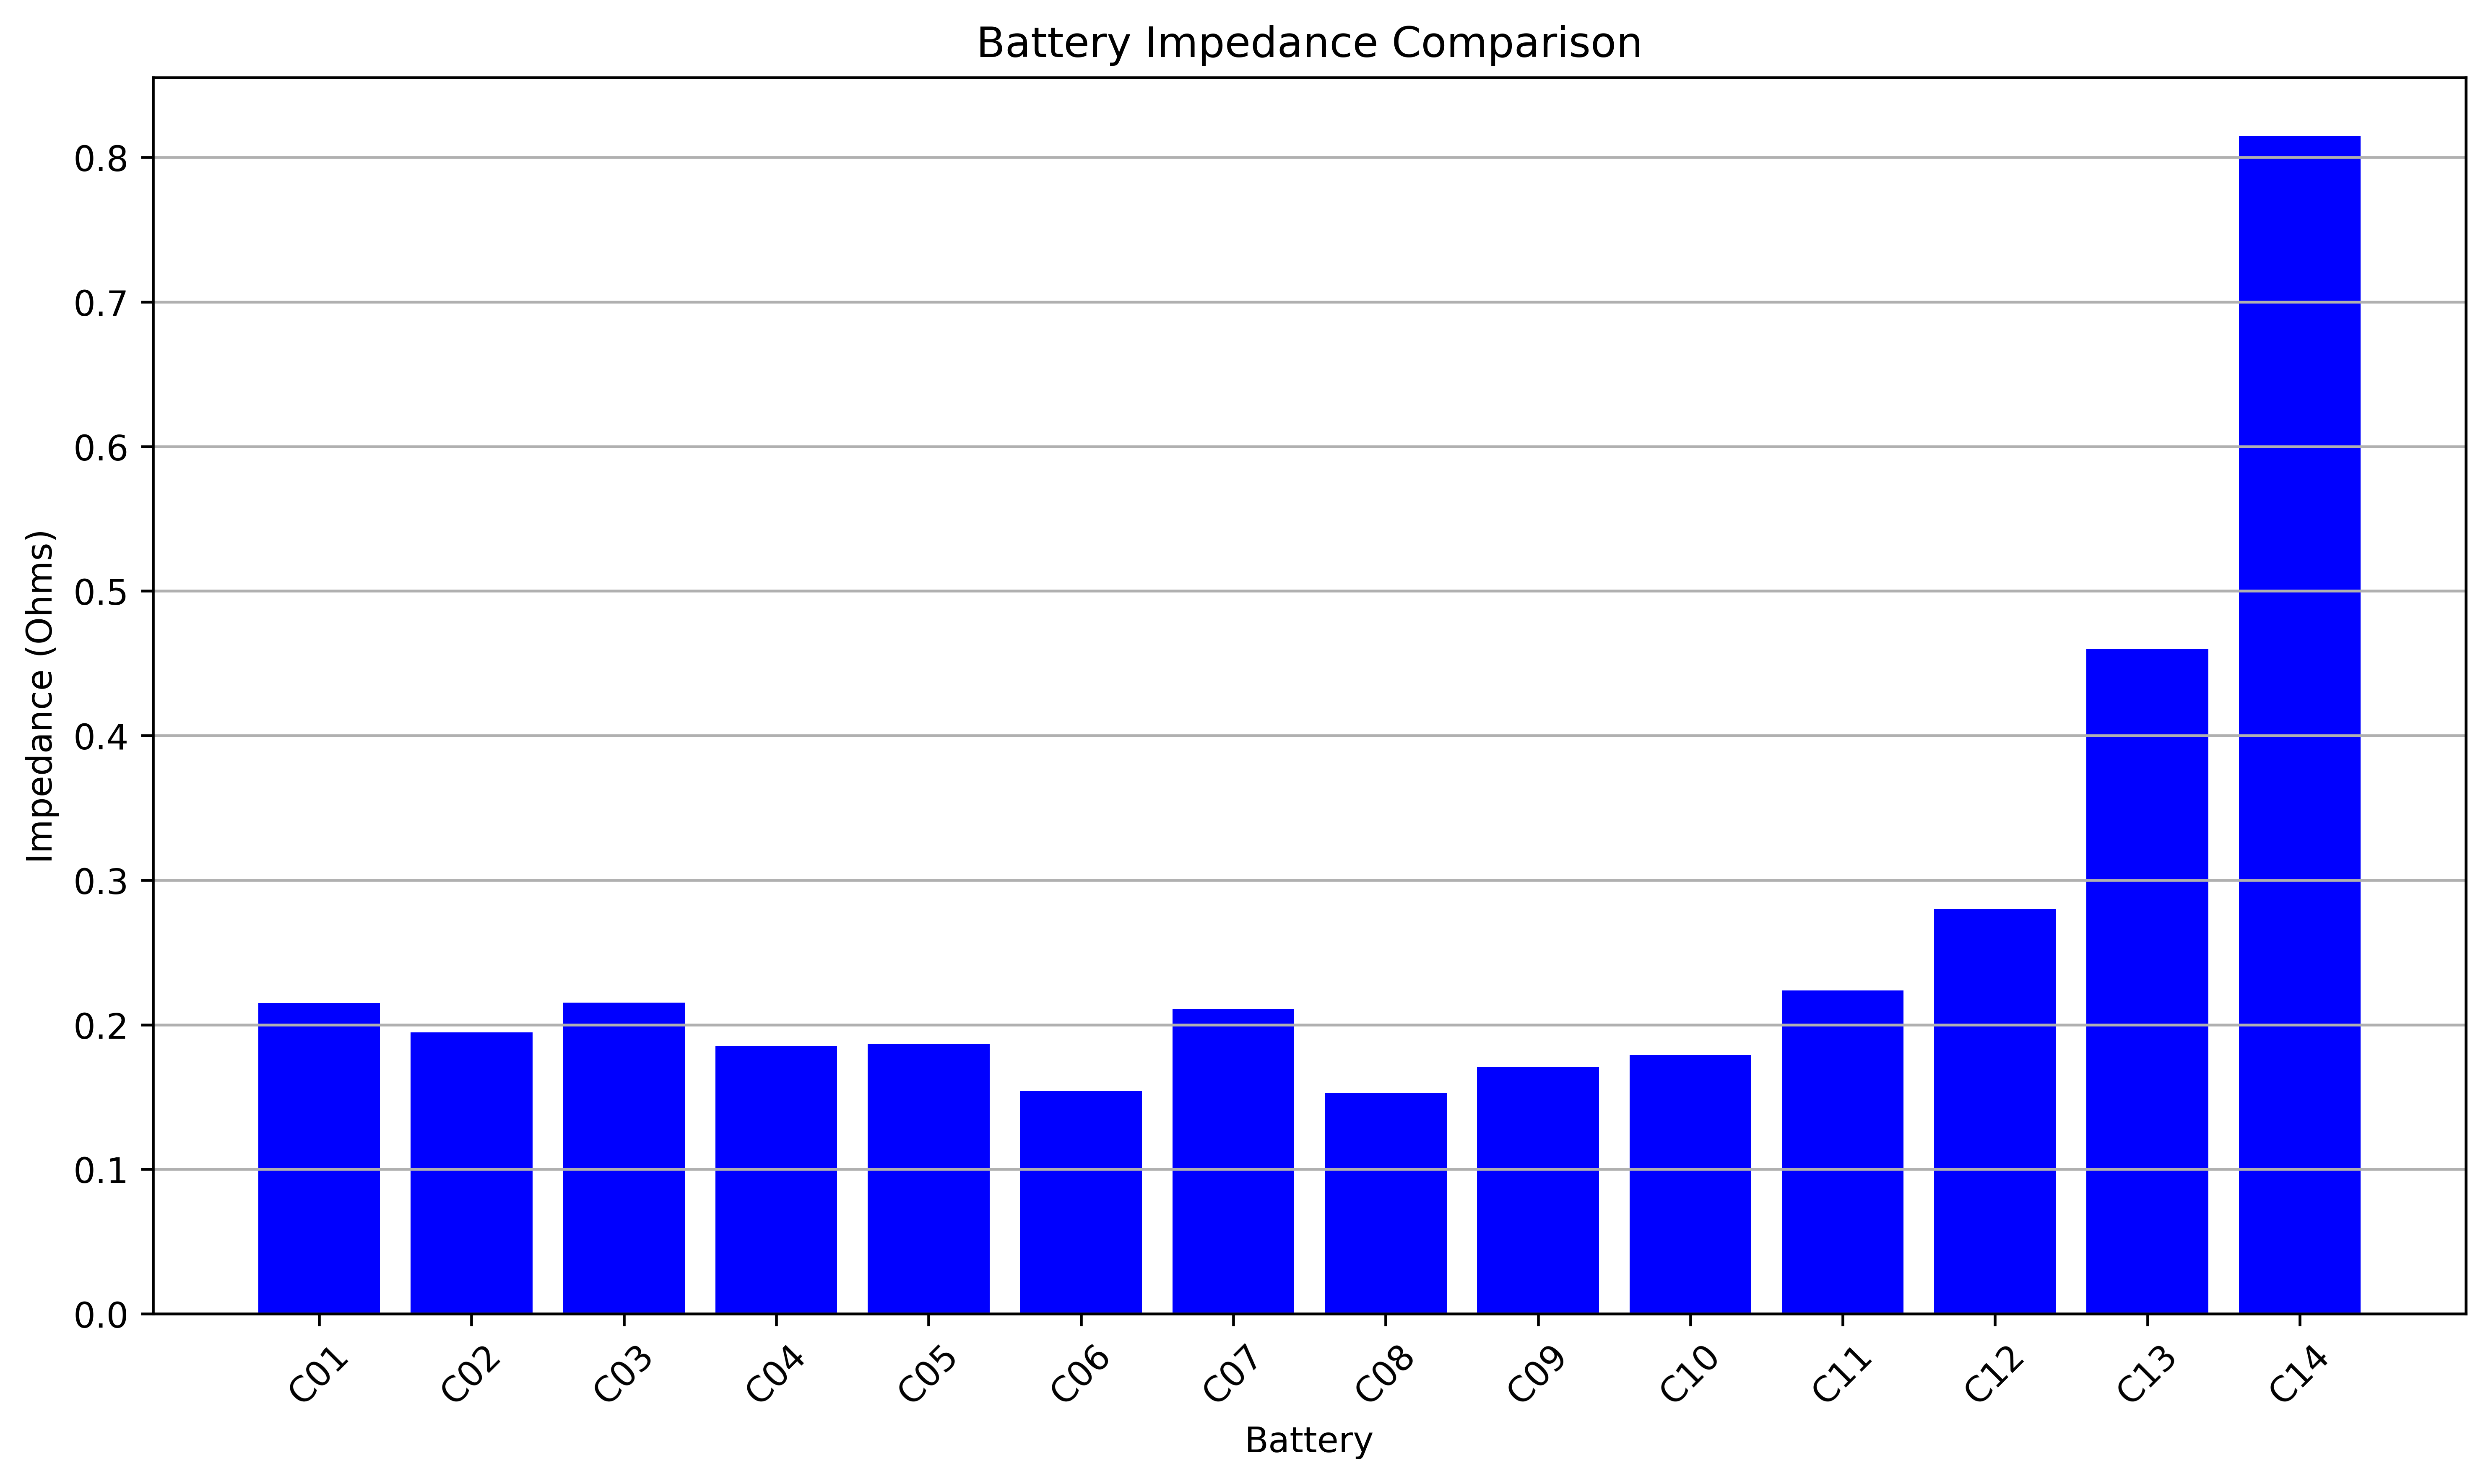

In [20]:
def plot_impedances(impedances: dict):
    batteries = list(impedances.keys())
    impedance_values = list(impedances.values())

    plt.figure(figsize=(10, 6))
    plt.bar(batteries, impedance_values, color="blue")
    plt.xlabel("Battery")
    plt.ylabel("Impedance (Ohms)")
    plt.title("Battery Impedance Comparison")
    plt.xticks(rotation=45)
    plt.grid(axis="y")
    plt.tight_layout()
    plt.show()


plot_impedances(impedances)

## Freezing Extent

In [21]:
def freezing_extent(vbatt_ht: float, vbatt_lt: float) -> float:
    if vbatt_ht > vbatt_lt:
        return 0.0  # Negative Thermal Gradient, No Freezing

    OFFSET = 1.824  # Linear zero offset of Cell Voltage to Electrolyte Concentration
    f = 1 - (vbatt_ht - OFFSET) / (vbatt_lt - OFFSET)
    return f


freezing_extents = {}

for battery in vbatt_df.index:
    vbatt_ht = vbatt_df.loc[battery, "VBATT HT"] / 6  # type: ignore
    vbatt_lt = vbatt_df.loc[battery, "VBATT LT"] / 6  # type: ignore

    f = freezing_extent(vbatt_ht=vbatt_ht, vbatt_lt=vbatt_lt)  # type: ignore

    freezing_extents[battery] = f

print(freezing_extents)

{'C01': 0.0, 'C02': 0.0, 'C03': 0.0, 'C04': 0.0, 'C05': 0.0, 'C06': 0.0, 'C07': np.float64(0.07642571739920212), 'C08': np.float64(0.10730972117558424), 'C09': np.float64(0.15963372758489214), 'C10': np.float64(0.22298362175525477), 'C11': np.float64(0.29276290108517455), 'C12': np.float64(0.36507923992746305), 'C13': np.float64(0.43283820475962287), 'C14': np.float64(0.512000967819985)}


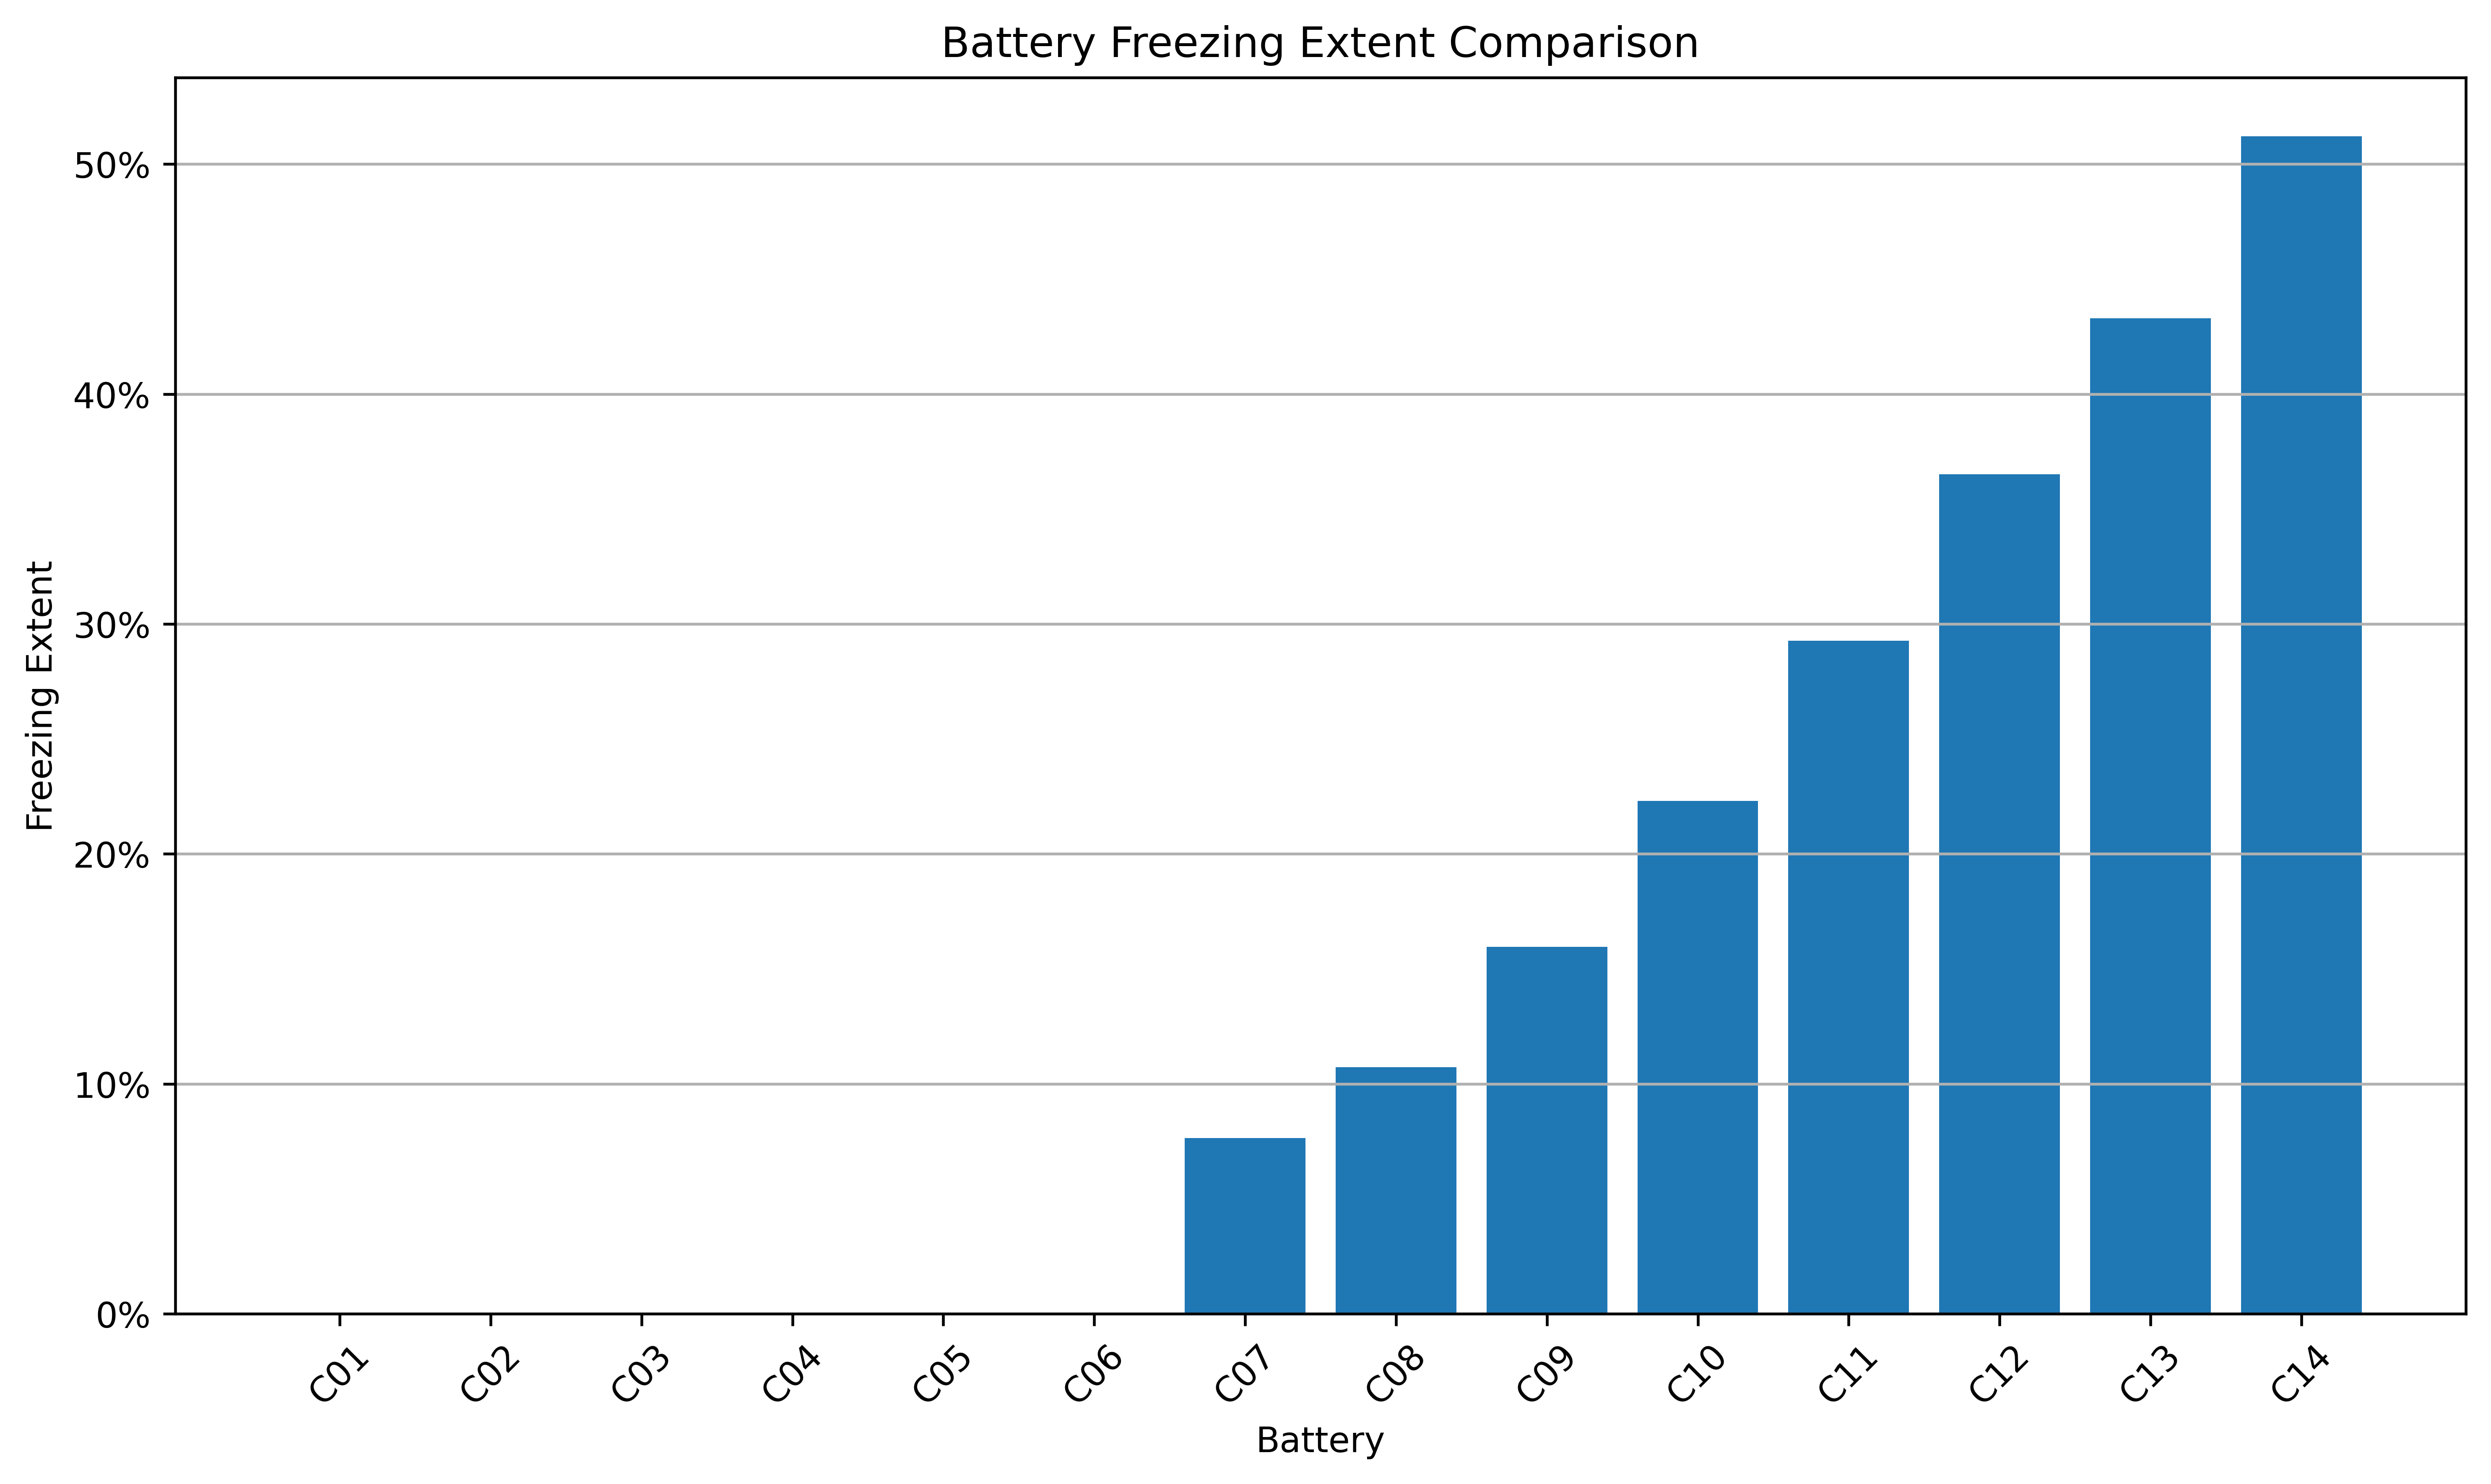

In [22]:
def plot_freezing_extents(freezing_extents: dict):
    batteries = list(freezing_extents.keys())
    freezing_values = list(freezing_extents.values())

    plt.figure(figsize=(10, 6))
    plt.bar(batteries, freezing_values)
    plt.xlabel("Battery")
    plt.ylabel("Freezing Extent")
    plt.gca().yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{100*y:.0f}%"))
    plt.title("Battery Freezing Extent Comparison")
    plt.xticks(rotation=45)
    plt.grid(axis="y")
    plt.tight_layout()
    plt.show()


plot_freezing_extents(freezing_extents)

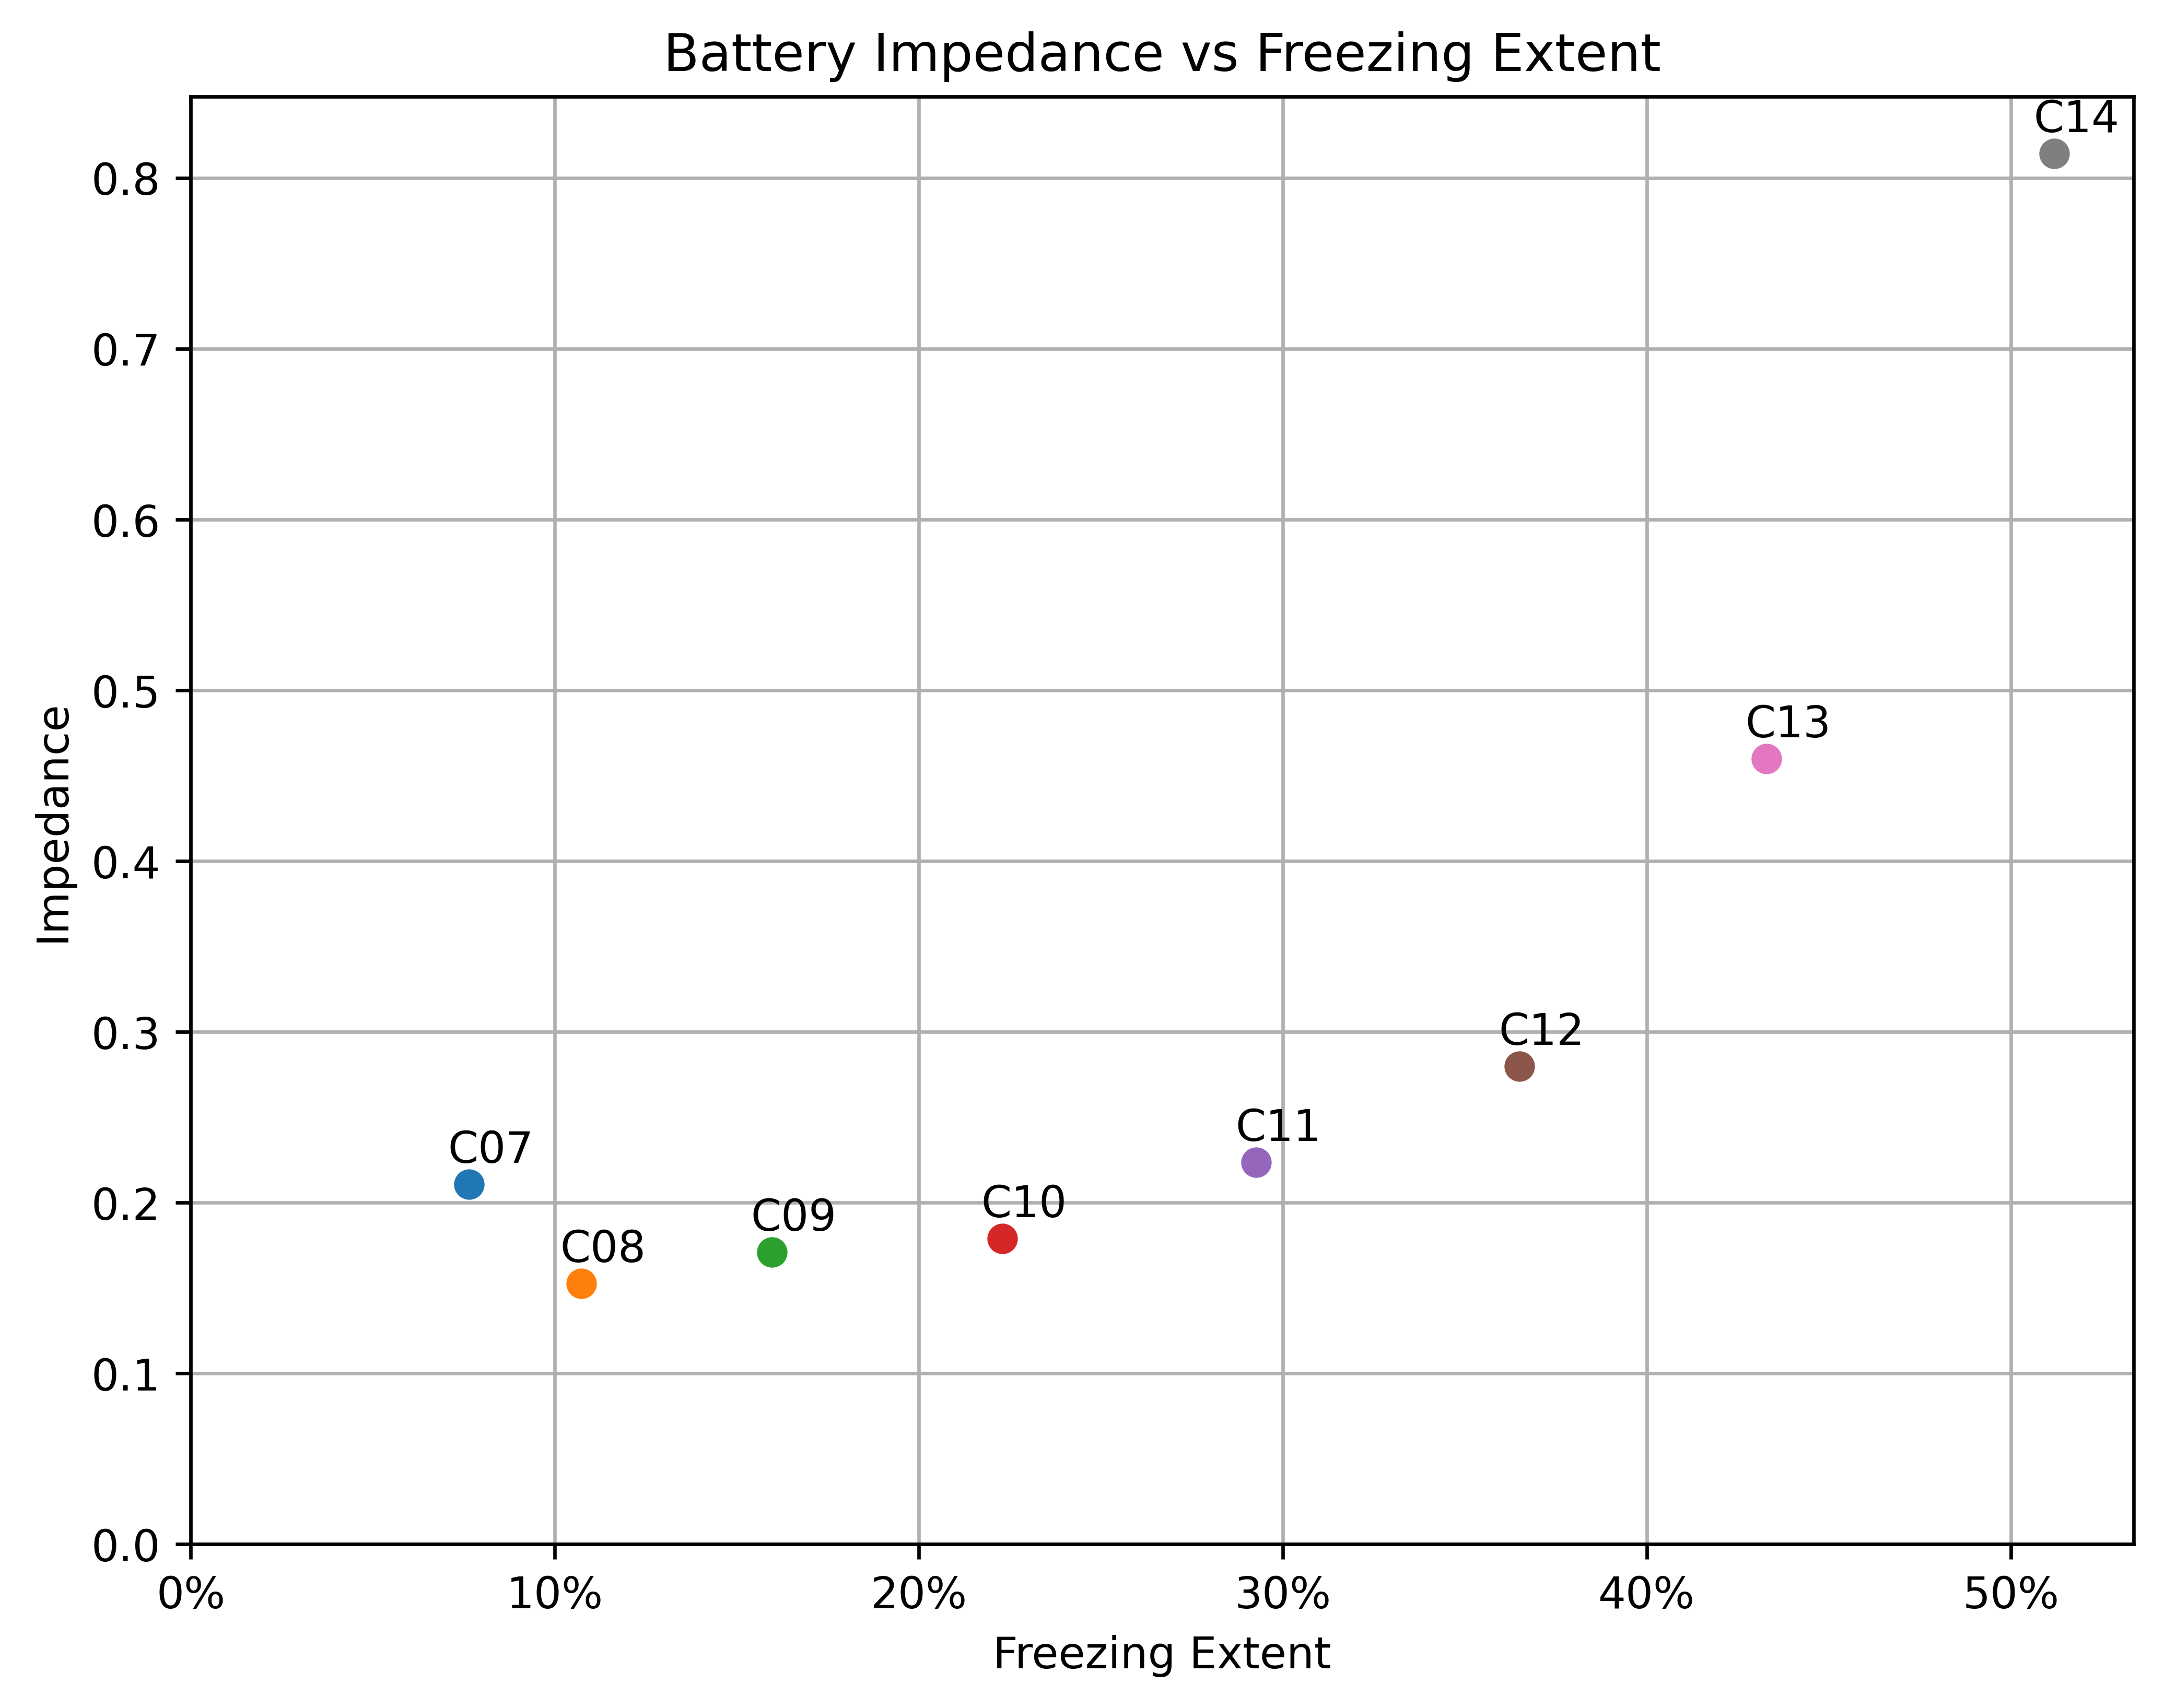

In [23]:
def plot_impedance_vs_freezing(
    impedances: dict,
    freezing_extents: dict,
    annotate: bool = False,
) -> Figure:
    fig, ax = plt.subplots(figsize=(8, 6))

    for battery in impedances.keys():
        impedance_value = impedances[battery]
        freezing_value = freezing_extents.get(battery, 0.0)

        if freezing_value > 0.0:
            ax.scatter(
                freezing_value,
                impedance_value,
                label=battery,
                color="black" if not annotate else None,
            )
            if annotate:
                ax.annotate(
                    battery,
                    (freezing_value, impedance_value),
                    textcoords="offset points",
                    xytext=(5, 5),
                    ha="center",
                )

    plt.ylabel("Impedance")
    plt.xlabel("Freezing Extent")
    plt.title("Battery Impedance vs Freezing Extent")
    plt.grid()

    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{100*x:.0f}%"))
    # ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:.2f}Ω"))

    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)

    return fig


_ = plot_impedance_vs_freezing(impedances, freezing_extents, annotate=True)

## Exports

Text(0.5, 1.0, '')

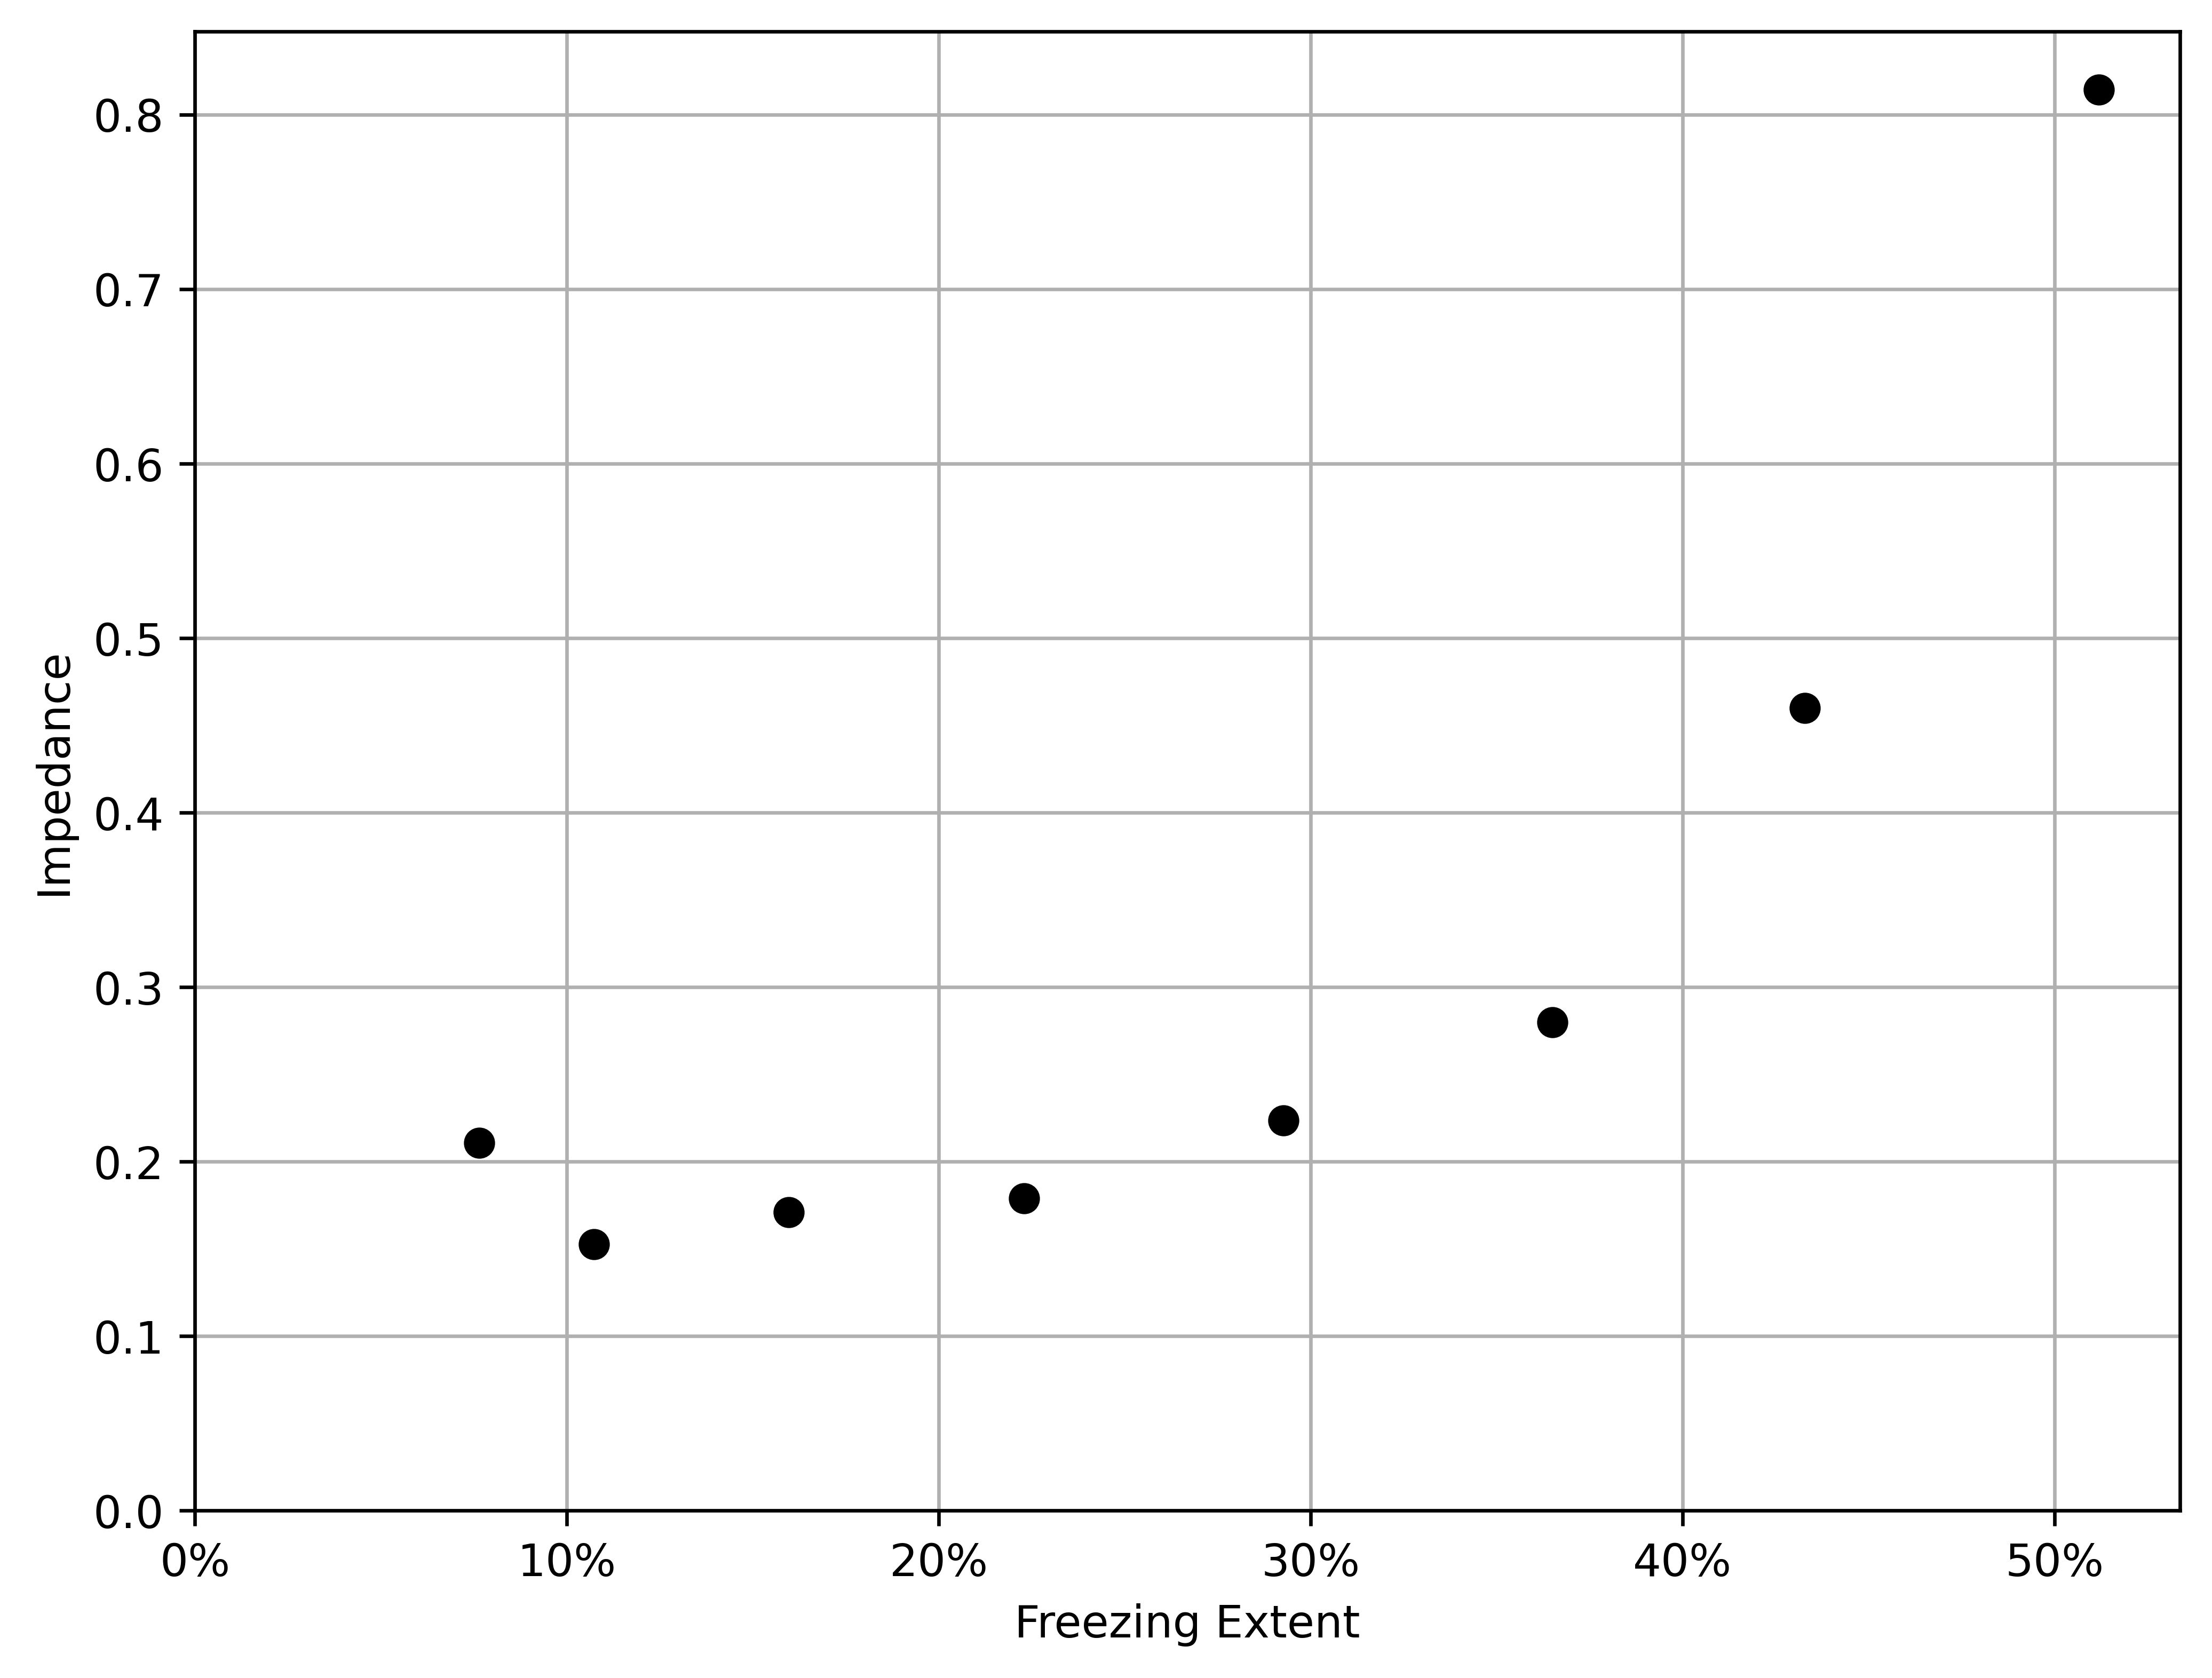

In [24]:
freezing_impedance_fig = plot_impedance_vs_freezing(
    impedances,
    freezing_extents,
    annotate=False,
)

freezing_impedance_fig.axes[0].set_title("")